# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen, Henry Fong, Edward Christopher

**Date:** 11/9/2026

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

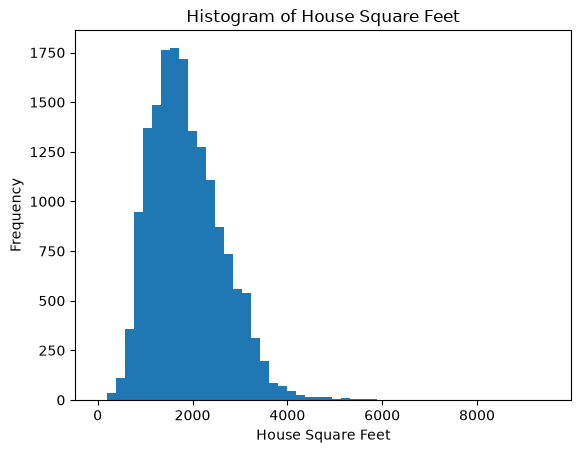

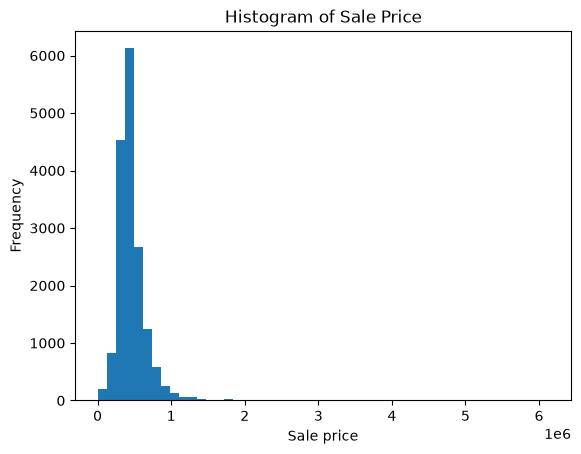

Model 1 Results:
Train RMSE: 200769.4407234562 and Train R2: 0.29058927620246167
Test RMSE:  185993.0860541432 and Test R2:  0.326660354485769
Model 2 Results:
Train RMSE: 166972.26958327874 and Train R2: 0.5093280500168363
Test RMSE:  159539.5011219844 and Test R2:  0.5045759964888721


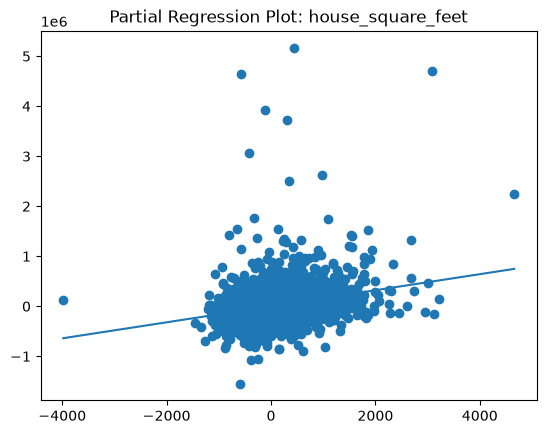

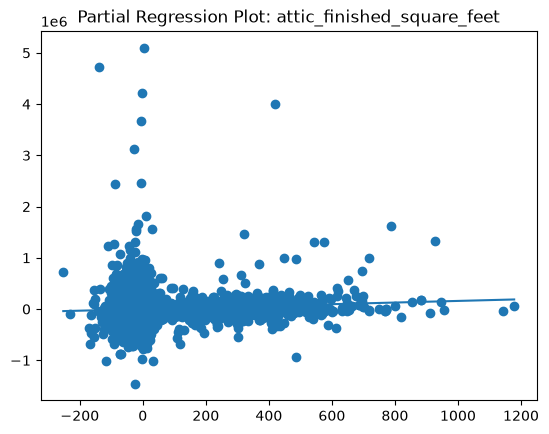

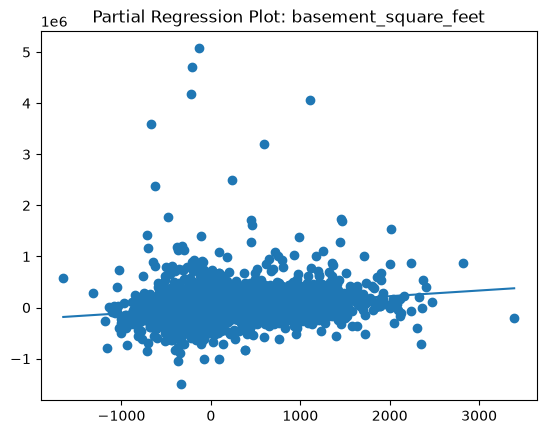

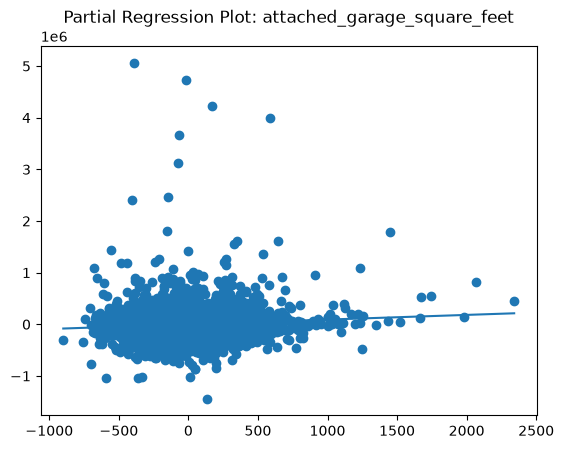

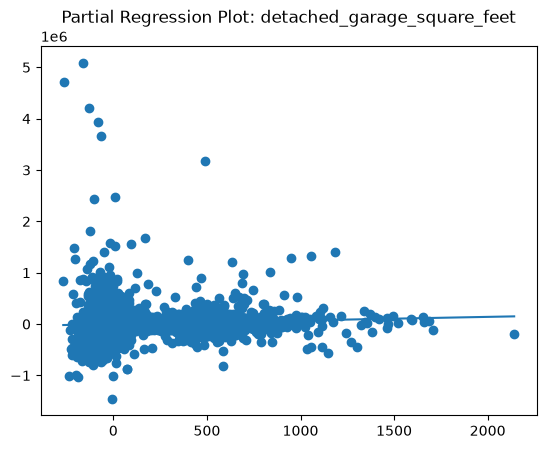

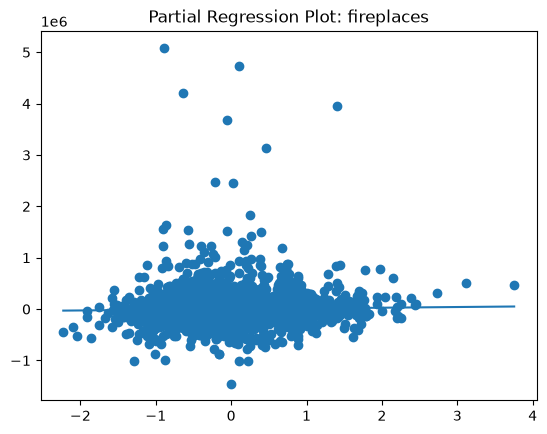

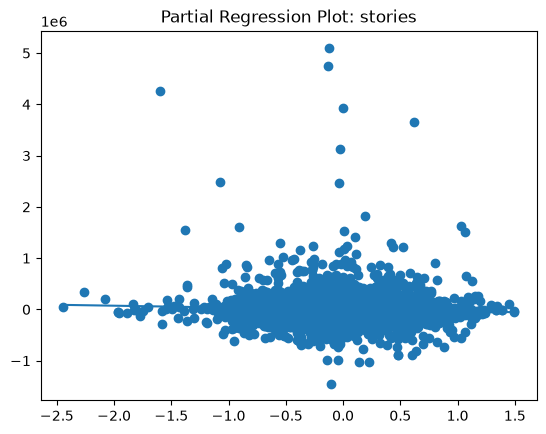

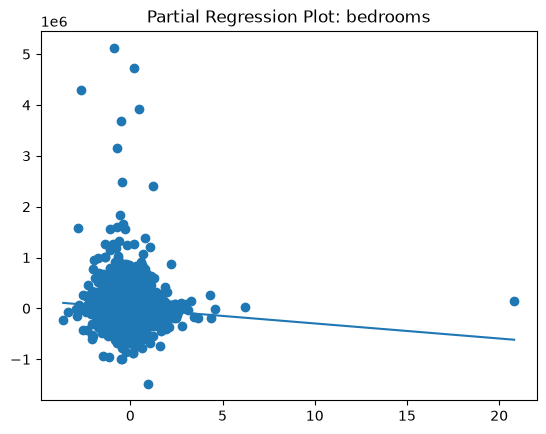

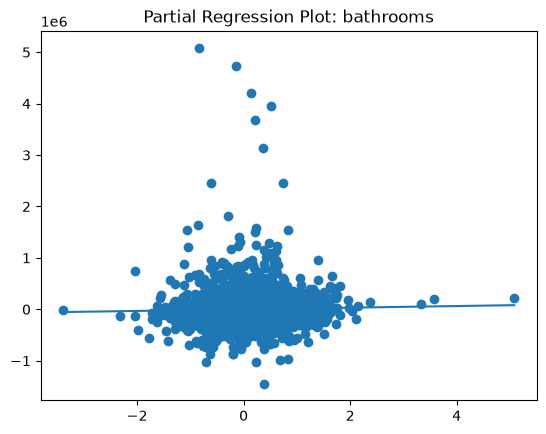

Complex Model Results:
Train RMSE: 186929.96707959563 and Train R2: 0.38502085297236077
Test RMSE:  171396.9538147154 and Test R2:  0.42819653428720605
Lasso Results:
Train RMSE: 166972.29758311601 | Train R2: 0.5093278854537511
Test RMSE:  159537.33909691026 | Test R2:  0.5045894240331812
 Top predictive features are:                                     Feature    Coefficient
23                    exterior_Frame Siding -321309.389265
25                     exterior_Frame Vinyl -296655.337393
13              hvac_description_Forced Air -264976.540660
10      hvac_description_Electric Baseboard -195486.780475
14               hvac_description_Heat Pump -167221.186456
17  hvac_description_Warm and Cool Air Zone -133741.397487
0                         house_square_feet  122218.995319
27            exterior_Masonry Common Brick -105315.482991
24                    exterior_Frame Stucco  -86853.692588
40                  waterfront_type_WF Salt   68171.574712


In [13]:
# Your Phase 1 solution to the problem goes here.

# Question 1
import pandas as pd
import matplotlib.pyplot as plt

path = "data/pierce_county_house_sales.csv"
df = pd.read_csv(path)

# Overview of dataset
df.info()
df.describe()

# Check for null values
print(df.isnull().sum())
print(df[df.isnull().any(axis=1)])

# Histograms for visualization
house_square_feet = df["house_square_feet"]
plt.hist(house_square_feet, bins=50)
plt.title("Histogram of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Frequency")
plt.show()

sale_price = df["sale_price"]
plt.hist(sale_price, bins=50)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale price")
plt.ylabel("Frequency")
plt.show()

# Question 2

# One-hot encode categorical variables
lst = ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]
df_encoded = pd.get_dummies(df, columns=lst, drop_first=True)

# Question 3
from sklearn.model_selection import train_test_split

# Define features and targets and split
X = df_encoded.drop(columns=["sale_price", "sale_date"])
y = df_encoded["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# Question 4
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Model 1
features_1 = ["house_square_feet", "bedrooms", "bathrooms"]
X_train_1 = X_train[features_1]
X_test_1 = X_test[features_1]

model1 = LinearRegression()
model1.fit(X_train_1, y_train)

train_pred_1 = model1.predict(X_train_1)
train_rmse_1 = np.sqrt(mean_squared_error(y_train, train_pred_1))
train_r2_1 = r2_score(y_train, train_pred_1)

test_pred_1 = model1.predict(X_test_1)
test_rmse_1 = np.sqrt(mean_squared_error(y_test, test_pred_1))
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1 Results:")
print(f"Train RMSE: {train_rmse_1} and Train R2: {train_r2_1}")
print(f"Test RMSE:  {test_rmse_1} and Test R2:  {test_r2_1}")

# Model 2
model2 = LinearRegression()
model2.fit(X_train, y_train)

train_pred_2 = model2.predict(X_train)
train_rmse_2 = np.sqrt(mean_squared_error(y_train, train_pred_2))
train_r2_2 = r2_score(y_train, train_pred_2)

test_pred_2 = model2.predict(X_test)
test_rmse_2 = np.sqrt(mean_squared_error(y_test, test_pred_2))
test_r2_2 = r2_score(y_test, test_pred_2)

print("Model 2 Results:")
print(f"Train RMSE: {train_rmse_2} and Train R2: {train_r2_2}")
print(f"Test RMSE:  {test_rmse_2} and Test R2:  {test_r2_2}")

# It looks like model 2 performed much better than model 1, as model 2 had higher R2 values and lower RMSE values.
# This is probably because model 1 only has three features but model 2 has more that all contribute to predicting the house sale price.

# Question 5

# Code from linear models lecture slides
def mlr(X, y):
    b = np.linalg.solve(X.T @ X, X.T @ y)  # solve for all coefficients
    y_hat = X @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}

numerical_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms"]

train_df = X_train.astype(float).copy()
train_df["(Intercept)"] = 1
y_vals = y_train.astype(float).values

for column in numerical_features:
    # Keep out target feature
    other_columns = []
    for c in X_train.columns:
        if c != column:
            other_columns.append(c)
    
    # Partial out other features from price
    features_for_price = ["(Intercept)"] + other_columns
    X_price = train_df[features_for_price]
    fit_price = mlr(X_price.values, y_vals)
    residual_price = fit_price["residuals"]
    
    # Partial out other features from the feature of interest
    features_for_features_of_interest = ["(Intercept)"] + other_columns
    X_feat = train_df[features_for_features_of_interest]
    fit_feature = mlr(X_feat.values, train_df[column].values)
    residual_feature = fit_feature["residuals"]
    
    # Regress price residuals on feature residuals
    X_residuals = pd.DataFrame({"(Intercept)": 1, "r_feat": residual_feature})
    fit_partial = mlr(X_residuals.values, residual_price)
    
    # Plot
    sort_index = np.argsort(residual_feature)
    plt.scatter(residual_feature, residual_price)
    plt.plot(residual_feature[sort_index], fit_partial["y_hat"][sort_index])
    plt.title(f"Partial Regression Plot: {column}")
    plt.show()

# There are no significant non-lineararities as they are all straight and not curved
# Most of the partial regression plots have an upwards trend with the exception of stories and bedrooms meaning they are not as significant towards sale price as the other variables.
# House square feet looks like the variable most contributing to sales price.

# Question 6
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

# Log square feet
X_train_complex["log_square_feet"] = np.log(X_train_complex["house_square_feet"])
X_test_complex["log_square_feet"] = np.log(X_test_complex["house_square_feet"])

# Square square feet
X_train_complex["square_feet_squared"] = X_train_complex["house_square_feet"] ** 2
X_test_complex["square_feet_squared"] = X_test_complex["house_square_feet"] ** 2

# Interactions
X_train_complex["square_feet_times_bedrooms"] = X_train_complex["house_square_feet"] * X_train_complex["bedrooms"]
X_test_complex["square_feet_times_bedrooms"] = X_test_complex["house_square_feet"] * X_test_complex["bedrooms"]

X_train_complex["bedrooms_times_bathrooms"] = X_train_complex["bedrooms"] * X_train_complex["bathrooms"]
X_test_complex["bedrooms_times_bathrooms"] = X_test_complex["bedrooms"] * X_test_complex["bathrooms"]

# Log sale price
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

model_complex = LinearRegression()
model_complex.fit(X_train_complex, y_train_log)

train_predict_log = model_complex.predict(X_train_complex)
test_predict_log = model_complex.predict(X_test_complex)

train_predict_complex = np.exp(train_predict_log)
test_predict_complex = np.exp(test_predict_log)

train_rmse_complex = np.sqrt(mean_squared_error(y_train, train_predict_complex))
train_r2_complex = r2_score(y_train, train_predict_complex)

test_rmse_complex = np.sqrt(mean_squared_error(y_test, test_predict_complex))
test_r2_complex = r2_score(y_test, test_predict_complex)

print("Complex Model Results:")
print(f"Train RMSE: {train_rmse_complex} and Train R2: {train_r2_complex}")
print(f"Test RMSE:  {test_rmse_complex} and Test R2:  {test_r2_complex}")

# The complex model did much better than simple model 1, with lower RMSE and higher R2. This may have happened because simple model 1 was too simple with only 3 features so it performed worse.
# However, the complex model did worse than simple model 2, with higher RMSE and lower R2. This may have happened because complex model had too many transformations which made it overfit.

# Question 7
# We learned from the steps that overfitting is when we make the model too complicated, such as adding too many transformations (such as from complex model). Underfitting is when we have too little features (such as from simple model 1).
# We also learned that by comparing different models and their RMSE and R2, we can see how the different steps affect the performance as well as which one performs the best.
# In summary, after cleaning/exploring the data, categorical encoding variables, splitting the data for train and test, we found that simple model 1 performed the least (it had too less features), complex model performed the second best (it had too many transformations), and simple model 2 performed the best (it used all encoded features without transformations from complext model). 
# We also saw from partial regression plots that house square feet was the most significant variable related to sales price while the other variables were either not as significant or not at all.

# Question 8
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# From lasso lecture slides
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=20000)
)

lasso_pipeline.fit(X_train, y_train)

train_predict_pipeline = lasso_pipeline.predict(X_train)
test_pred_pipeline = lasso_pipeline.predict(X_test)

train_rmse_pipeline = np.sqrt(mean_squared_error(y_train, train_predict_pipeline))
train_r2_pipeline = r2_score(y_train, train_predict_pipeline)

test_rmse_pipeline = np.sqrt(mean_squared_error(y_test, test_pred_pipeline))
test_r2_pipeline = r2_score(y_test, test_pred_pipeline)

print("Lasso Results:")
print(f"Train RMSE: {train_rmse_pipeline} | Train R2: {train_r2_pipeline}")
print(f"Test RMSE:  {test_rmse_pipeline} | Test R2:  {test_r2_pipeline}")

selected_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_pipeline.named_steps["lasso"].coef_
})

top_predictive_features = selected_features.reindex(selected_features['Coefficient'].abs().sort_values(ascending=False).index)
print(f" Top predictive features are: {top_predictive_features.head(10)}")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e94288d89258581e55f551a62b4c2d78338905f9
- **AI tool and model used:** Gemini Flash-Lite

### *Prompts used

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

# Your Phase 1 solution to the problem goes here.

# Question 1
import pandas as pd
import matplotlib.pyplot as plt

path = "data/pierce_county_house_sales.csv"
df = pd.read_csv(path)

# Overview of dataset
df.info()
df.describe()

# Check for null values
print(df.isnull().sum())
print(df[df.isnull().any(axis=1)])

# Histograms for visualization
house_square_feet = df["house_square_feet"]
plt.hist(house_square_feet, bins=50)
plt.title("Histogram of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Frequency")
plt.show()

sale_price = df["sale_price"]
plt.hist(sale_price, bins=50)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale price")
plt.ylabel("Frequency")
plt.show()

# Question 2

# One-hot encode categorical variables
lst = ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]
df_encoded = pd.get_dummies(df, columns=lst, drop_first=True)

# Question 3
from sklearn.model_selection import train_test_split

# Define features and targets and split
X = df_encoded.drop(columns=["sale_price", "sale_date"])
y = df_encoded["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# Question 4
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Model 1
features_1 = ["house_square_feet", "bedrooms", "bathrooms"]
X_train_1 = X_train[features_1]
X_test_1 = X_test[features_1]

model1 = LinearRegression()
model1.fit(X_train_1, y_train)

train_pred_1 = model1.predict(X_train_1)
train_rmse_1 = np.sqrt(mean_squared_error(y_train, train_pred_1))
train_r2_1 = r2_score(y_train, train_pred_1)

test_pred_1 = model1.predict(X_test_1)
test_rmse_1 = np.sqrt(mean_squared_error(y_test, test_pred_1))
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1 Results:")
print(f"Train RMSE: {train_rmse_1} and Train R2: {train_r2_1}")
print(f"Test RMSE:  {test_rmse_1} and Test R2:  {test_r2_1}")

# Model 2
model2 = LinearRegression()
model2.fit(X_train, y_train)

train_pred_2 = model2.predict(X_train)
train_rmse_2 = np.sqrt(mean_squared_error(y_train, train_pred_2))
train_r2_2 = r2_score(y_train, train_pred_2)

test_pred_2 = model2.predict(X_test)
test_rmse_2 = np.sqrt(mean_squared_error(y_test, test_pred_2))
test_r2_2 = r2_score(y_test, test_pred_2)

print("Model 2 Results:")
print(f"Train RMSE: {train_rmse_2} and Train R2: {train_r2_2}")
print(f"Test RMSE:  {test_rmse_2} and Test R2:  {test_r2_2}")

# It looks like model 2 performed much better than model 1, as model 2 had higher R2 values and lower RMSE values.
# This is probably because model 1 only has three features but model 2 has more that all contribute to predicting the house sale price.

# Question 5

# Code from linear models lecture slides
def mlr(X, y):
    b = np.linalg.solve(X.T @ X, X.T @ y)  # solve for all coefficients
    y_hat = X @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}

numerical_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms"]

train_df = X_train.astype(float).copy()
train_df["(Intercept)"] = 1
y_vals = y_train.astype(float).values

for column in numerical_features:
    # Keep out target feature
    other_columns = []
    for c in X_train.columns:
        if c != column:
            other_columns.append(c)
    
    # Partial out other features from price
    features_for_price = ["(Intercept)"] + other_columns
    X_price = train_df[features_for_price]
    fit_price = mlr(X_price.values, y_vals)
    residual_price = fit_price["residuals"]
    
    # Partial out other features from the feature of interest
    features_for_features_of_interest = ["(Intercept)"] + other_columns
    X_feat = train_df[features_for_features_of_interest]
    fit_feature = mlr(X_feat.values, train_df[column].values)
    residual_feature = fit_feature["residuals"]
    
    # Regress price residuals on feature residuals
    X_residuals = pd.DataFrame({"(Intercept)": 1, "r_feat": residual_feature})
    fit_partial = mlr(X_residuals.values, residual_price)
    
    # Plot
    sort_index = np.argsort(residual_feature)
    plt.scatter(residual_feature, residual_price)
    plt.plot(residual_feature[sort_index], fit_partial["y_hat"][sort_index])
    plt.title(f"Partial Regression Plot: {column}")
    plt.show()

# There are no significant non-lineararities as they are all straight and not curved
# Most of the partial regression plots have an upwards trend with the exception of stories and bedrooms meaning they are not as significant towards sale price as the other variables.
# House square feet looks like the variable most contributing to sales price.

# Question 6
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

# Log square feet
X_train_complex["log_square_feet"] = np.log(X_train_complex["house_square_feet"])
X_test_complex["log_square_feet"] = np.log(X_test_complex["house_square_feet"])

# Square square feet
X_train_complex["square_feet_squared"] = X_train_complex["house_square_feet"] ** 2
X_test_complex["square_feet_squared"] = X_test_complex["house_square_feet"] ** 2

# Interactions
X_train_complex["square_feet_times_bedrooms"] = X_train_complex["house_square_feet"] * X_train_complex["bedrooms"]
X_test_complex["square_feet_times_bedrooms"] = X_test_complex["house_square_feet"] * X_test_complex["bedrooms"]

X_train_complex["bedrooms_times_bathrooms"] = X_train_complex["bedrooms"] * X_train_complex["bathrooms"]
X_test_complex["bedrooms_times_bathrooms"] = X_test_complex["bedrooms"] * X_test_complex["bathrooms"]

# Log sale price
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

model_complex = LinearRegression()
model_complex.fit(X_train_complex, y_train_log)

train_predict_log = model_complex.predict(X_train_complex)
test_predict_log = model_complex.predict(X_test_complex)

train_predict_complex = np.exp(train_predict_log)
test_predict_complex = np.exp(test_predict_log)

train_rmse_complex = np.sqrt(mean_squared_error(y_train, train_predict_complex))
train_r2_complex = r2_score(y_train, train_predict_complex)

test_rmse_complex = np.sqrt(mean_squared_error(y_test, test_predict_complex))
test_r2_complex = r2_score(y_test, test_predict_complex)

print("Complex Model Results:")
print(f"Train RMSE: {train_rmse_complex} and Train R2: {train_r2_complex}")
print(f"Test RMSE:  {test_rmse_complex} and Test R2:  {test_r2_complex}")

# The complex model did much better than simple model 1, with lower RMSE and higher R2. This may have happened because simple model 1 was too simple with only 3 features so it performed worse.
# However, the complex model did worse than simple model 2, with higher RMSE and lower R2. This may have happened because complex model had too many transformations which made it overfit.

# Question 7
# We learned from the steps that overfitting is when we make the model too complicated, such as adding too many transformations (such as from complex model). Underfitting is when we have too little features (such as from simple model 1).
# We also learned that by comparing different models and their RMSE and R2, we can see how the different steps affect the performance as well as which one performs the best.
# In summary, after cleaning/exploring the data, categorical encoding variables, splitting the data for train and test, we found that simple model 1 performed the least (it had too less features), complex model performed the second best (it had too many transformations), and simple model 2 performed the best (it used all encoded features without transformations from complext model). 
# We also saw from partial regression plots that house square feet was the most significant variable related to sales price while the other variables were either not as significant or not at all.

# Question 8
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# From lasso lecture slides
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=20000)
)

lasso_pipeline.fit(X_train, y_train)

train_predict_pipeline = lasso_pipeline.predict(X_train)
test_pred_pipeline = lasso_pipeline.predict(X_test)

train_rmse_pipeline = np.sqrt(mean_squared_error(y_train, train_predict_pipeline))
train_r2_pipeline = r2_score(y_train, train_predict_pipeline)

test_rmse_pipeline = np.sqrt(mean_squared_error(y_test, test_pred_pipeline))
test_r2_pipeline = r2_score(y_test, test_pred_pipeline)

print("Lasso Results:")
print(f"Train RMSE: {train_rmse_pipeline} | Train R2: {train_r2_pipeline}")
print(f"Test RMSE:  {test_rmse_pipeline} | Test R2:  {test_r2_pipeline}")

selected_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_pipeline.named_steps["lasso"].coef_
})

top_predictive_features = selected_features.reindex(selected_features['Coefficient'].abs().sort_values(ascending=False).index)
print(f" Top predictive features are: {top_predictive_features.head(10)}")

Here is my code:
```
# Your Phase 1 solution to the problem goes here.

# Question 1
import pandas as pd
import matplotlib.pyplot as plt

path = "data/pierce_county_house_sales.csv"
df = pd.read_csv(path)

# Overview of dataset
df.info()
df.describe()

# Check for null values
print(df.isnull().sum())
print(df[df.isnull().any(axis=1)])

# Histograms for visualization
house_square_feet = df["house_square_feet"]
plt.hist(house_square_feet, bins=50)
plt.title("Histogram of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Frequency")
plt.show()

sale_price = df["sale_price"]
plt.hist(sale_price, bins=50)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale price")
plt.ylabel("Frequency")
plt.show()

# Question 2

# One-hot encode categorical variables
lst = ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]
df_encoded = pd.get_dummies(df, columns=lst, drop_first=True)

# Question 3
from sklearn.model_selection import train_test_split

# Define features and targets and split
X = df_encoded.drop(columns=["sale_price", "sale_date"])
y = df_encoded["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# Question 4
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Model 1
features_1 = ["house_square_feet", "bedrooms", "bathrooms"]
X_train_1 = X_train[features_1]
X_test_1 = X_test[features_1]

model1 = LinearRegression()
model1.fit(X_train_1, y_train)

train_pred_1 = model1.predict(X_train_1)
train_rmse_1 = np.sqrt(mean_squared_error(y_train, train_pred_1))
train_r2_1 = r2_score(y_train, train_pred_1)

test_pred_1 = model1.predict(X_test_1)
test_rmse_1 = np.sqrt(mean_squared_error(y_test, test_pred_1))
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1 Results:")
print(f"Train RMSE: {train_rmse_1} and Train R2: {train_r2_1}")
print(f"Test RMSE:  {test_rmse_1} and Test R2:  {test_r2_1}")

# Model 2
model2 = LinearRegression()
model2.fit(X_train, y_train)

train_pred_2 = model2.predict(X_train)
train_rmse_2 = np.sqrt(mean_squared_error(y_train, train_pred_2))
train_r2_2 = r2_score(y_train, train_pred_2)

test_pred_2 = model2.predict(X_test)
test_rmse_2 = np.sqrt(mean_squared_error(y_test, test_pred_2))
test_r2_2 = r2_score(y_test, test_pred_2)

print("Model 2 Results:")
print(f"Train RMSE: {train_rmse_2} and Train R2: {train_r2_2}")
print(f"Test RMSE:  {test_rmse_2} and Test R2:  {test_r2_2}")

# It looks like model 2 performed much better than model 1, as model 2 had higher R2 values and lower RMSE values.
# This is probably because model 1 only has three features but model 2 has more that all contribute to predicting the house sale price.

# Question 5

# Code from linear models lecture slides
def mlr(X, y):
    b = np.linalg.solve(X.T @ X, X.T @ y)  # solve for all coefficients
    y_hat = X @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}

numerical_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms"]

train_df = X_train.astype(float).copy()
train_df["(Intercept)"] = 1
y_vals = y_train.astype(float).values

for column in numerical_features:
    # Keep out target feature
    other_columns = []
    for c in X_train.columns:
        if c != column:
            other_columns.append(c)
    
    # Partial out other features from price
    features_for_price = ["(Intercept)"] + other_columns
    X_price = train_df[features_for_price]
    fit_price = mlr(X_price.values, y_vals)
    residual_price = fit_price["residuals"]
    
    # Partial out other features from the feature of interest
    features_for_features_of_interest = ["(Intercept)"] + other_columns
    X_feat = train_df[features_for_features_of_interest]
    fit_feature = mlr(X_feat.values, train_df[column].values)
    residual_feature = fit_feature["residuals"]
    
    # Regress price residuals on feature residuals
    X_residuals = pd.DataFrame({"(Intercept)": 1, "r_feat": residual_feature})
    fit_partial = mlr(X_residuals.values, residual_price)
    
    # Plot
    sort_index = np.argsort(residual_feature)
    plt.scatter(residual_feature, residual_price)
    plt.plot(residual_feature[sort_index], fit_partial["y_hat"][sort_index])
    plt.title(f"Partial Regression Plot: {column}")
    plt.show()

# There are no significant non-lineararities as they are all straight and not curved
# Most of the partial regression plots have an upwards trend with the exception of stories and bedrooms meaning they are not as significant towards sale price as the other variables.
# House square feet looks like the variable most contributing to sales price.

# Question 6
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

# Log square feet
X_train_complex["log_square_feet"] = np.log(X_train_complex["house_square_feet"])
X_test_complex["log_square_feet"] = np.log(X_test_complex["house_square_feet"])

# Square square feet
X_train_complex["square_feet_squared"] = X_train_complex["house_square_feet"] ** 2
X_test_complex["square_feet_squared"] = X_test_complex["house_square_feet"] ** 2

# Interactions
X_train_complex["square_feet_times_bedrooms"] = X_train_complex["house_square_feet"] * X_train_complex["bedrooms"]
X_test_complex["square_feet_times_bedrooms"] = X_test_complex["house_square_feet"] * X_test_complex["bedrooms"]

X_train_complex["bedrooms_times_bathrooms"] = X_train_complex["bedrooms"] * X_train_complex["bathrooms"]
X_test_complex["bedrooms_times_bathrooms"] = X_test_complex["bedrooms"] * X_test_complex["bathrooms"]

# Log sale price
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

model_complex = LinearRegression()
model_complex.fit(X_train_complex, y_train_log)

train_predict_log = model_complex.predict(X_train_complex)
test_predict_log = model_complex.predict(X_test_complex)

train_predict_complex = np.exp(train_predict_log)
test_predict_complex = np.exp(test_predict_log)

train_rmse_complex = np.sqrt(mean_squared_error(y_train, train_predict_complex))
train_r2_complex = r2_score(y_train, train_predict_complex)

test_rmse_complex = np.sqrt(mean_squared_error(y_test, test_predict_complex))
test_r2_complex = r2_score(y_test, test_predict_complex)

print("Complex Model Results:")
print(f"Train RMSE: {train_rmse_complex} and Train R2: {train_r2_complex}")
print(f"Test RMSE:  {test_rmse_complex} and Test R2:  {test_r2_complex}")

# The complex model did much better than simple model 1, with lower RMSE and higher R2. This may have happened because simple model 1 was too simple with only 3 features so it performed worse.
# However, the complex model did worse than simple model 2, with higher RMSE and lower R2. This may have happened because complex model had too many transformations which made it overfit.

# Question 7
# We learned from the steps that overfitting is when we make the model too complicated, such as adding too many transformations (such as from complex model). Underfitting is when we have too little features (such as from simple model 1).
# We also learned that by comparing different models and their RMSE and R2, we can see how the different steps affect the performance as well as which one performs the best.
# In summary, after cleaning/exploring the data, categorical encoding variables, splitting the data for train and test, we found that simple model 1 performed the least (it had too less features), complex model performed the second best (it had too many transformations), and simple model 2 performed the best (it used all encoded features without transformations from complext model). 
# We also saw from partial regression plots that house square feet was the most significant variable related to sales price while the other variables were either not as significant or not at all.

# Question 8
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# From lasso lecture slides
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=20000)
)

lasso_pipeline.fit(X_train, y_train)

train_predict_pipeline = lasso_pipeline.predict(X_train)
test_pred_pipeline = lasso_pipeline.predict(X_test)

train_rmse_pipeline = np.sqrt(mean_squared_error(y_train, train_predict_pipeline))
train_r2_pipeline = r2_score(y_train, train_predict_pipeline)

test_rmse_pipeline = np.sqrt(mean_squared_error(y_test, test_pred_pipeline))
test_r2_pipeline = r2_score(y_test, test_pred_pipeline)

print("Lasso Results:")
print(f"Train RMSE: {train_rmse_pipeline} | Train R2: {train_r2_pipeline}")
print(f"Test RMSE:  {test_rmse_pipeline} | Test R2:  {test_r2_pipeline}")

selected_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_pipeline.named_steps["lasso"].coef_
})

top_predictive_features = selected_features.reindex(selected_features['Coefficient'].abs().sort_values(ascending=False).index)
print(f" Top predictive features are: {top_predictive_features.head(10)}")
```
Give me feedback 

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. The Catch: While your EDA checks for null values (df.isnull().sum()), neither LinearRegression nor Lasso in scikit-learn can handle NaN values.

Suggestion: Add an explicit imputation step (e.g., filling missing numerical values with the median or dropping rows/columns with excessive missingness) right after inspecting nulls in Question 1 so your regression fits run smoothly without throwing a ValueError.
2. The Catch: In Question 6, you trained your complex model on log(y), predicted on the log scale, and then exponentiated (np.exp()) to compute RMSE and $R^2$ on the original dollar scale.Why it matters: When you optimize Mean Squared Error on $\log(y)$, your model predicts the geometric mean (median) of $y$. When exponentiated back to dollars, it estimates the median rather than the expected value, which can artificially inflate RMSE on the original scale compared to a model trained directly on dollar values. Furthermore, unregularized polynomial features and interactions can easily overfit even when trained on log targets.Suggestion: Try running the complex model directly on the original target scale $y$ (or use proper Duan's smearing estimator / correction if evaluating on log scale) to see if the higher test RMSE was purely a artifact of the loss function scale mismatch.
3. The Catch: You correctly implemented a pipeline with StandardScaler() and Lasso(max_iter=20000), but left alpha at its default value (alpha=1.0).Why it matters: Depending on the scale of your features and target, a default alpha=1.0 might be too aggressive (shrinking too many coefficients to zero) or too weak.Suggestion: Replace Lasso with sklearn.linear_model.LassoCV (which automatically performs cross-validation across a grid of alpha values) to find the optimal regularization strength and maximize your test set $R^2$.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | In our EDA, we saw that there are no NaN values so there is no worry of that. |
| 2 | reject | It may be correct but for our assignment, the slides tell us to log the price for transformation |
| 3 | accept | We did not change the alpha value so that could help make our results better if we did |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

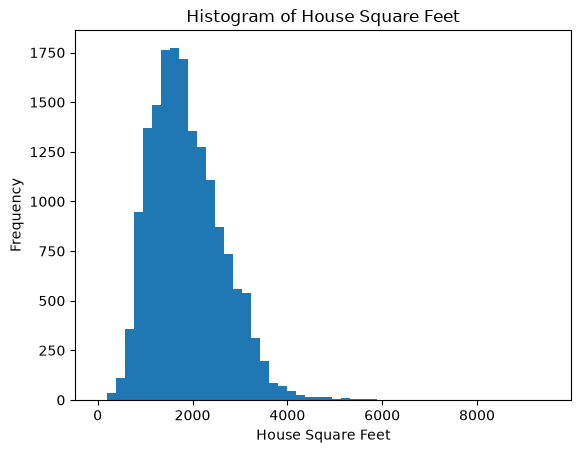

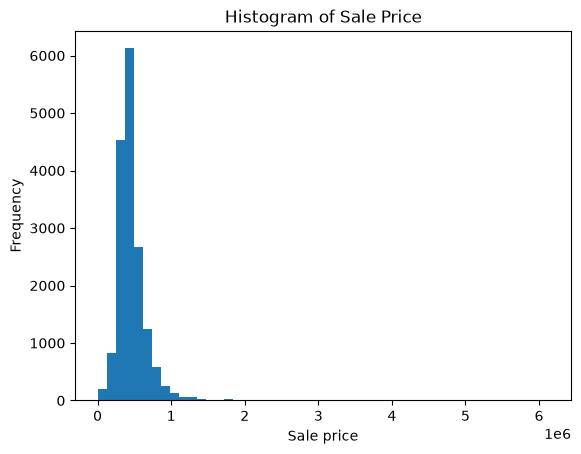

Model 1 Results:
Train RMSE: 200769.4407234562 and Train R2: 0.29058927620246167
Test RMSE:  185993.0860541432 and Test R2:  0.326660354485769
Model 2 Results:
Train RMSE: 166972.26958327874 and Train R2: 0.5093280500168363
Test RMSE:  159539.5011219844 and Test R2:  0.5045759964888721


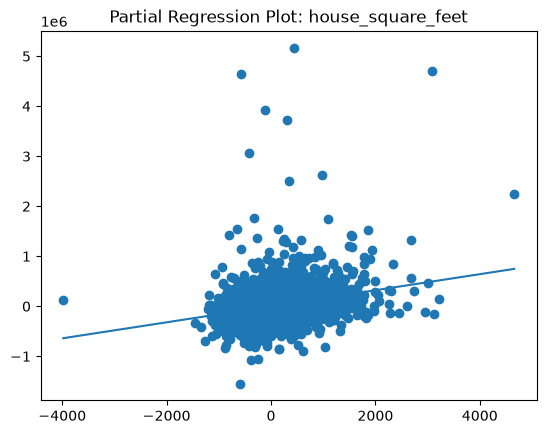

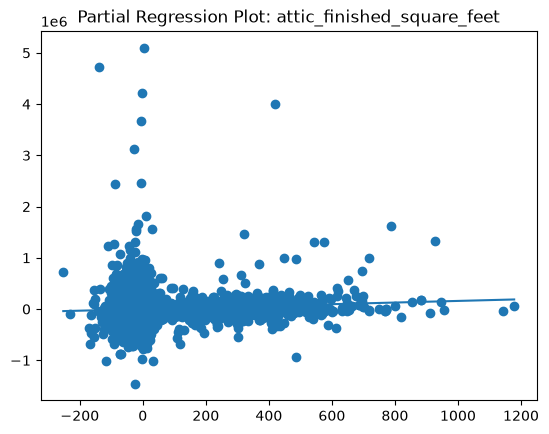

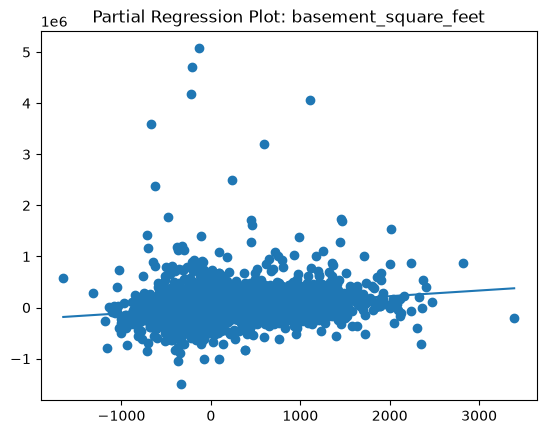

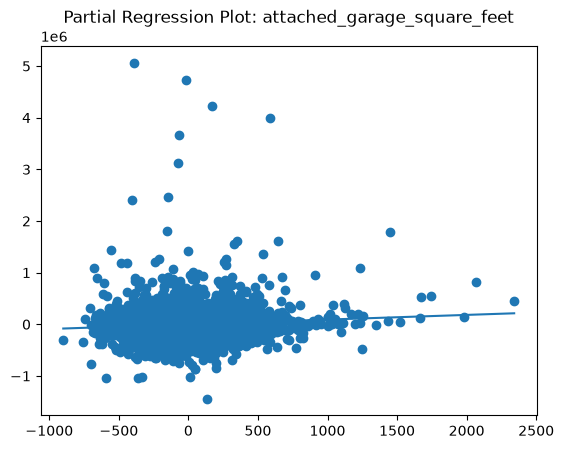

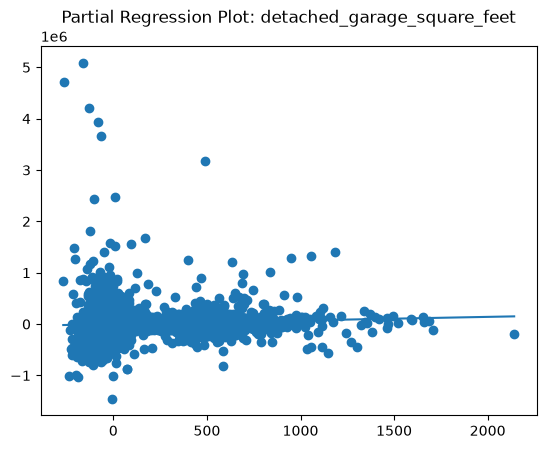

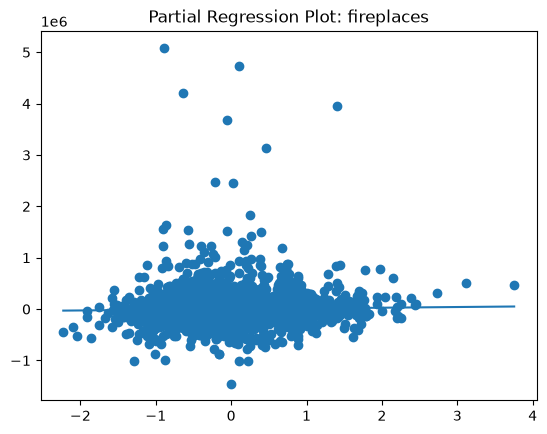

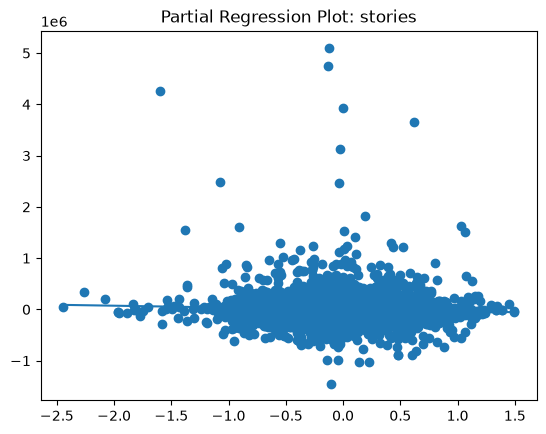

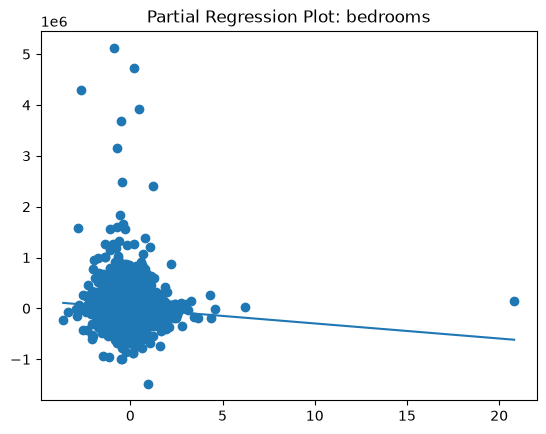

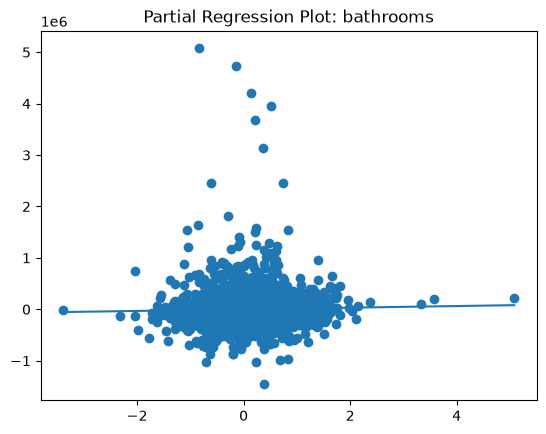

Complex Model Results:
Train RMSE: 186929.96707959563 and Train R2: 0.38502085297236077
Test RMSE:  171396.9538147154 and Test R2:  0.42819653428720605
Lasso Results:
Train RMSE: 167239.03807530878 | Train R2: 0.5077589226232657
Test RMSE:  159365.71898471657 | Test R2:  0.5056547130527671
 Top predictive features are:                                     Feature    Coefficient
23                    exterior_Frame Siding -184642.175388
25                     exterior_Frame Vinyl -175411.235358
13              hvac_description_Forced Air -138187.101279
0                         house_square_feet  121988.975740
10      hvac_description_Electric Baseboard -100194.156309
14               hvac_description_Heat Pump  -80879.996151
40                  waterfront_type_WF Salt   68192.090583
17  hvac_description_Warm and Cool Air Zone  -64516.190971
27            exterior_Masonry Common Brick  -59321.546571
2                      basement_square_feet   47710.938272


In [15]:
# Your Phase 2 solution to the problem goes here.

# Question 1
import pandas as pd
import matplotlib.pyplot as plt

path = "data/pierce_county_house_sales.csv"
df = pd.read_csv(path)

# Overview of dataset
df.info()
df.describe()

# Check for null values
print(df.isnull().sum())
print(df[df.isnull().any(axis=1)])

# Histograms for visualization
house_square_feet = df["house_square_feet"]
plt.hist(house_square_feet, bins=50)
plt.title("Histogram of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Frequency")
plt.show()

sale_price = df["sale_price"]
plt.hist(sale_price, bins=50)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale price")
plt.ylabel("Frequency")
plt.show()

# Question 2

# One-hot encode categorical variables
lst = ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]
df_encoded = pd.get_dummies(df, columns=lst, drop_first=True)

# Question 3
from sklearn.model_selection import train_test_split

# Define features and targets and split
X = df_encoded.drop(columns=["sale_price", "sale_date"])
y = df_encoded["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# Question 4
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Model 1
features_1 = ["house_square_feet", "bedrooms", "bathrooms"]
X_train_1 = X_train[features_1]
X_test_1 = X_test[features_1]

model1 = LinearRegression()
model1.fit(X_train_1, y_train)

train_pred_1 = model1.predict(X_train_1)
train_rmse_1 = np.sqrt(mean_squared_error(y_train, train_pred_1))
train_r2_1 = r2_score(y_train, train_pred_1)

test_pred_1 = model1.predict(X_test_1)
test_rmse_1 = np.sqrt(mean_squared_error(y_test, test_pred_1))
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1 Results:")
print(f"Train RMSE: {train_rmse_1} and Train R2: {train_r2_1}")
print(f"Test RMSE:  {test_rmse_1} and Test R2:  {test_r2_1}")

# Model 2
model2 = LinearRegression()
model2.fit(X_train, y_train)

train_pred_2 = model2.predict(X_train)
train_rmse_2 = np.sqrt(mean_squared_error(y_train, train_pred_2))
train_r2_2 = r2_score(y_train, train_pred_2)

test_pred_2 = model2.predict(X_test)
test_rmse_2 = np.sqrt(mean_squared_error(y_test, test_pred_2))
test_r2_2 = r2_score(y_test, test_pred_2)

print("Model 2 Results:")
print(f"Train RMSE: {train_rmse_2} and Train R2: {train_r2_2}")
print(f"Test RMSE:  {test_rmse_2} and Test R2:  {test_r2_2}")

# It looks like model 2 performed much better than model 1, as model 2 had higher R2 values and lower RMSE values.
# This is probably because model 1 only has three features but model 2 has more that all contribute to predicting the house sale price.

# Question 5

# Code from linear models lecture slides
def mlr(X, y):
    b = np.linalg.solve(X.T @ X, X.T @ y)  # solve for all coefficients
    y_hat = X @ b
    residuals = y - y_hat
    sse = np.inner(residuals, residuals)
    rsq = 1 - sse / np.inner(y - np.mean(y), y - np.mean(y))
    return {"b": b, "y_hat": y_hat, "residuals": residuals,
            "rsq": rsq, "SSE": sse}

numerical_features = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet", "attached_garage_square_feet", "detached_garage_square_feet", "fireplaces", "stories", "bedrooms", "bathrooms"]

train_df = X_train.astype(float).copy()
train_df["(Intercept)"] = 1
y_vals = y_train.astype(float).values

for column in numerical_features:
    # Keep out target feature
    other_columns = []
    for c in X_train.columns:
        if c != column:
            other_columns.append(c)
    
    # Partial out other features from price
    features_for_price = ["(Intercept)"] + other_columns
    X_price = train_df[features_for_price]
    fit_price = mlr(X_price.values, y_vals)
    residual_price = fit_price["residuals"]
    
    # Partial out other features from the feature of interest
    features_for_features_of_interest = ["(Intercept)"] + other_columns
    X_feat = train_df[features_for_features_of_interest]
    fit_feature = mlr(X_feat.values, train_df[column].values)
    residual_feature = fit_feature["residuals"]
    
    # Regress price residuals on feature residuals
    X_residuals = pd.DataFrame({"(Intercept)": 1, "r_feat": residual_feature})
    fit_partial = mlr(X_residuals.values, residual_price)
    
    # Plot
    sort_index = np.argsort(residual_feature)
    plt.scatter(residual_feature, residual_price)
    plt.plot(residual_feature[sort_index], fit_partial["y_hat"][sort_index])
    plt.title(f"Partial Regression Plot: {column}")
    plt.show()

# There are no significant non-lineararities as they are all straight and not curved
# Most of the partial regression plots have an upwards trend with the exception of stories and bedrooms meaning they are not as significant towards sale price as the other variables.
# House square feet looks like the variable most contributing to sales price.

# Question 6
X_train_complex = X_train.copy()
X_test_complex = X_test.copy()

# Log square feet
X_train_complex["log_square_feet"] = np.log(X_train_complex["house_square_feet"])
X_test_complex["log_square_feet"] = np.log(X_test_complex["house_square_feet"])

# Square square feet
X_train_complex["square_feet_squared"] = X_train_complex["house_square_feet"] ** 2
X_test_complex["square_feet_squared"] = X_test_complex["house_square_feet"] ** 2

# Interactions
X_train_complex["square_feet_times_bedrooms"] = X_train_complex["house_square_feet"] * X_train_complex["bedrooms"]
X_test_complex["square_feet_times_bedrooms"] = X_test_complex["house_square_feet"] * X_test_complex["bedrooms"]

X_train_complex["bedrooms_times_bathrooms"] = X_train_complex["bedrooms"] * X_train_complex["bathrooms"]
X_test_complex["bedrooms_times_bathrooms"] = X_test_complex["bedrooms"] * X_test_complex["bathrooms"]

# Log sale price
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

model_complex = LinearRegression()
model_complex.fit(X_train_complex, y_train_log)

train_predict_log = model_complex.predict(X_train_complex)
test_predict_log = model_complex.predict(X_test_complex)

train_predict_complex = np.exp(train_predict_log)
test_predict_complex = np.exp(test_predict_log)

train_rmse_complex = np.sqrt(mean_squared_error(y_train, train_predict_complex))
train_r2_complex = r2_score(y_train, train_predict_complex)

test_rmse_complex = np.sqrt(mean_squared_error(y_test, test_predict_complex))
test_r2_complex = r2_score(y_test, test_predict_complex)

print("Complex Model Results:")
print(f"Train RMSE: {train_rmse_complex} and Train R2: {train_r2_complex}")
print(f"Test RMSE:  {test_rmse_complex} and Test R2:  {test_r2_complex}")

# The complex model did much better than simple model 1, with lower RMSE and higher R2. This may have happened because simple model 1 was too simple with only 3 features so it performed worse.
# However, the complex model did worse than simple model 2, with higher RMSE and lower R2. This may have happened because complex model had too many transformations which made it overfit.

# Question 7
# We learned from the steps that overfitting is when we make the model too complicated, such as adding too many transformations (such as from complex model). Underfitting is when we have too little features (such as from simple model 1).
# We also learned that by comparing different models and their RMSE and R2, we can see how the different steps affect the performance as well as which one performs the best.
# In summary, after cleaning/exploring the data, categorical encoding variables, splitting the data for train and test, we found that simple model 1 performed the least (it had too less features), complex model performed the second best (it had too many transformations), and simple model 2 performed the best (it used all encoded features without transformations from complext model). 
# We also saw from partial regression plots that house square feet was the most significant variable related to sales price while the other variables were either not as significant or not at all.

# Question 8
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# From lasso lecture slides
lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(alpha=100.0, max_iter=20000)
)

lasso_pipeline.fit(X_train, y_train)

train_predict_pipeline = lasso_pipeline.predict(X_train)
test_pred_pipeline = lasso_pipeline.predict(X_test)

train_rmse_pipeline = np.sqrt(mean_squared_error(y_train, train_predict_pipeline))
train_r2_pipeline = r2_score(y_train, train_predict_pipeline)

test_rmse_pipeline = np.sqrt(mean_squared_error(y_test, test_pred_pipeline))
test_r2_pipeline = r2_score(y_test, test_pred_pipeline)

print("Lasso Results:")
print(f"Train RMSE: {train_rmse_pipeline} | Train R2: {train_r2_pipeline}")
print(f"Test RMSE:  {test_rmse_pipeline} | Test R2:  {test_r2_pipeline}")

selected_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_pipeline.named_steps["lasso"].coef_
})

top_predictive_features = selected_features.reindex(selected_features['Coefficient'].abs().sort_values(ascending=False).index)
print(f" Top predictive features are: {top_predictive_features.head(10)}")

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI gave us many suggestions, often providing us with nuances that we did not think of before. However, most of these nuances were not relevant to our assignment. For example, it told us that we had to watch out for NaN values since linear regression nor lasso could handle those values which is true but for our dataset, we found no NaN values so that was not needed. Another suggestion was to not log transform the sales price but our assignment slides tell us to do so. Thus, if the suggestions it gave were on a more real-world project, it would be more helpful rather than one that is on an assignment. A helpful suggestion that it gave was specifying the alpha value for Lasso, which we did to try to get better results. The final solution was verified by seeing if the Ai's suggestions were reasonable and stayed true to the assignment's requirements. We have no other concerns. 